# Семинар 3. Свёрточные сети, аугментации, transfer learning

Семинар идёт сразу после лекции 3 «CNN: свёртки, архитектуры, transfer learning».
На лекции свёртка была операцией на слайде — здесь мы её потрогаем руками
и проверим на опыте три тезиса, которые там прозвучали как утверждения.

**Что сделаем:**

1. Соберём датасет, на котором видно то, ради чего нужны свёртки: цифру кладём
   в произвольное место холста.
2. Применим свёртку руками — ядром Собеля, без всякого обучения.
3. Посчитаем параметры и операции свёрточного слоя и сверим с формулами лекции.
4. Измерим рецептивное поле **градиентом** и сверим с формулой `RF = 1 + L·(k−1)`.
5. **Сравним полносвязную сеть и свёрточную при одинаковом числе параметров** —
   и посмотрим, что с ними делает сдвиг картинки.
6. Добавим аугментации: увидим, какая помогает, а какая портит.
7. **Сделаем transfer learning**: предобучим сеть на цифрах 0–4 и перенесём
   на 5–9, где данных мало. Сравним три режима из лекции.
8. Подключим **настоящий ImageNet-бэкбон** — ResNet18 из `torchvision`: увидим,
   как ломает его неправильный препроцессинг и выигрывает ли он у нашего.

**Как запускать.** Ноутбук работает и в Google Colab, и локально. Локально нужно:

```
pip install torch torchvision matplotlib scikit-learn
```

Данные лежат внутри `scikit-learn`, в разделах 1–7 «предобученную» сеть мы обучаем
сами тут же. Интернет нужен только в разделе 8: он один раз скачивает веса ResNet18
(около 45 МБ). Полный прогон — несколько минут на CPU.

⚠️ **Материала больше, чем на 90 минут.** Ядро — разделы **1, 5, 6 и 7**
(данные, CNN против полносвязной, аугментации, transfer learning). Разделы 2, 3 и 4 —
проверка отдельных формул лекции, каждый самостоятелен и любой можно пропустить
или оставить на самостоятельное чтение. Раздел 8 — продолжение раздела 7
на настоящем бэкбоне, его можно разобрать, если останется время.

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)

# Считаем на CPU намеренно: модели крошечные, на видеокарте они не ускорятся,
# всё время уйдёт на пересылку данных. Заодно результаты у всех совпадут.
device = "cpu"
print("PyTorch:", torch.__version__)

PyTorch: 2.8.0


---

## 1. Данные: цифра в произвольном месте холста

Берём `digits` из `scikit-learn` — 1797 рукописных цифр 8×8, датасет лежит внутри пакета.
Но использовать его как есть нельзя: **8×8 — это слишком мелко, чтобы свёртка и пулинг
успели что-то показать**, и, главное, цифра там всегда в одном и том же месте.

Поэтому строим свой датасет: кладём цифру 8×8 на холст 20×20 в выбранную позицию
и добавляем немного шума. Позиция — это ручка, которой мы будем крутить задачу:

- `mode="jitter", jitter=0` — цифра строго в центре, всегда одинаково;
- `mode="jitter", jitter=2` — центр плюс-минус два пикселя;
- `mode="random"` — цифра в любом из 13×13 = 169 возможных положений.

Именно на этой ручке и держится весь семинар: полносвязная сеть видит картинку как
вектор из 400 чисел, и для неё «двойка в левом верхнем углу» и «двойка в правом нижнем» —
два совершенно разных объекта.

In [2]:
from sklearn.datasets import load_digits

CANVAS = 20          # размер холста
DIGIT = 8            # размер картинки цифры
MAX_OFF = CANVAS - DIGIT   # 12 — максимальный сдвиг по каждой оси
NOISE = 0.15         # шум, чтобы задача не решалась совсем уж тривиально

digits = load_digits()
IMAGES = digits.images.astype(np.float32) / 16.0     # значения 0…16 → 0…1
LABELS = digits.target.astype(np.int64)


def place(images, rng, mode="random", jitter=1, noise=NOISE):
    """Кладёт каждую цифру 8×8 на холст CANVAS×CANVAS и добавляет шум.

    mode="random" — позиция равномерно по всем 13×13 вариантам;
    mode="jitter" — центр ± jitter пикселей (jitter=0 значит «строго в центре»).
    """
    out = np.zeros((len(images), 1, CANVAS, CANVAS), np.float32)
    centre = MAX_OFF // 2
    for i, img in enumerate(images):
        if mode == "random":
            r0, c0 = rng.integers(0, MAX_OFF + 1, 2)
        else:
            r0 = np.clip(centre + rng.integers(-jitter, jitter + 1), 0, MAX_OFF)
            c0 = np.clip(centre + rng.integers(-jitter, jitter + 1), 0, MAX_OFF)
        out[i, 0, r0:r0 + DIGIT, c0:c0 + DIGIT] = img
    if noise:
        out = np.clip(out + rng.normal(0, noise, out.shape).astype(np.float32), 0, None)
    return out


rng = np.random.default_rng(0)
perm = rng.permutation(len(IMAGES))
i_train, i_test = perm[:1300], perm[1300:]
y_train, y_test = LABELS[i_train], LABELS[i_test]

# Обучающая выборка: цифра СТРОГО В ЦЕНТРЕ. Это принципиально — так у полносвязной
# сети есть честный шанс, и разница на тесте будет видна именно из-за сдвига.
X_train = place(IMAGES[i_train], np.random.default_rng(1), "jitter", jitter=0)

# Два теста: «как учили» и «то же самое, но сдвинуто».
X_test_centre = place(IMAGES[i_test], np.random.default_rng(2), "jitter", jitter=0)
X_test_shift  = place(IMAGES[i_test], np.random.default_rng(3), "random")

print("обучение:", X_train.shape, "| тест:", X_test_centre.shape)

обучение: (1300, 1, 20, 20) | тест: (497, 1, 20, 20)


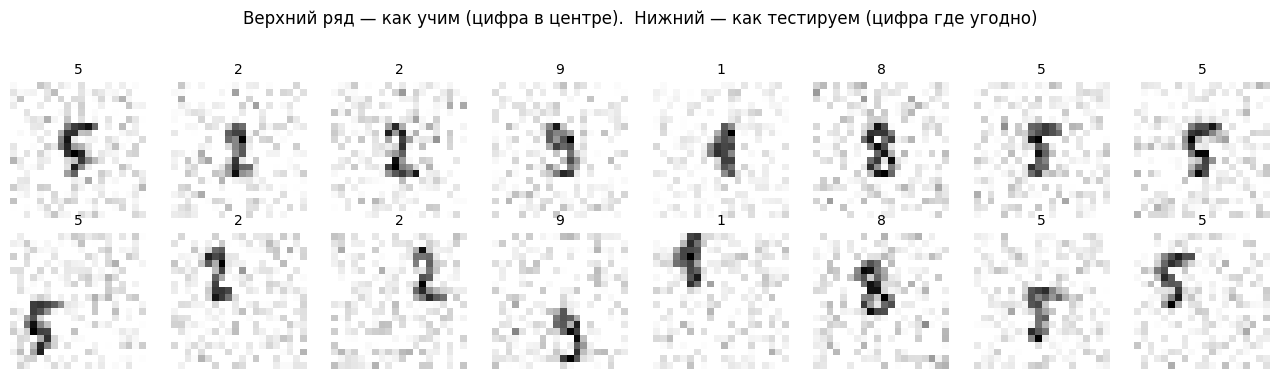

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for ax, img, lab in zip(axes[0], X_test_centre, y_test):
    ax.imshow(img[0], cmap="gray_r"); ax.set_title(lab, fontsize=10); ax.axis("off")
for ax, img, lab in zip(axes[1], X_test_shift, y_test):
    ax.imshow(img[0], cmap="gray_r"); ax.set_title(lab, fontsize=10); ax.axis("off")
axes[0][0].set_ylabel("центр"); axes[1][0].set_ylabel("сдвиг")
fig.suptitle("Верхний ряд — как учим (цифра в центре).  "
             "Нижний — как тестируем (цифра где угодно)", y=1.04)
plt.tight_layout(); plt.show()

---

## 2. Свёртка руками: ядро Собеля

На лекции свёртка вводилась как операция, у которой ядро можно **задать**, а можно
**выучить**. Начнём с первого: возьмём готовые ядра Собеля и посмотрим, что они
находят на картинке. Никакого обучения здесь нет — это просто `F.conv2d`
с руками написанными весами.

⚠️ Терминологическая ловушка со слайда 9: то, что в PyTorch называется `Conv2d`,
математически является **корреляцией** — ядро не отражается. Разница видна ровно
на несимметричных ядрах вроде Собеля: знак результата получится противоположным
математической свёртке. На обучаемых слоях это не важно (сеть выучит то ядро,
которое нужно), но при ручном задании весов — важно.

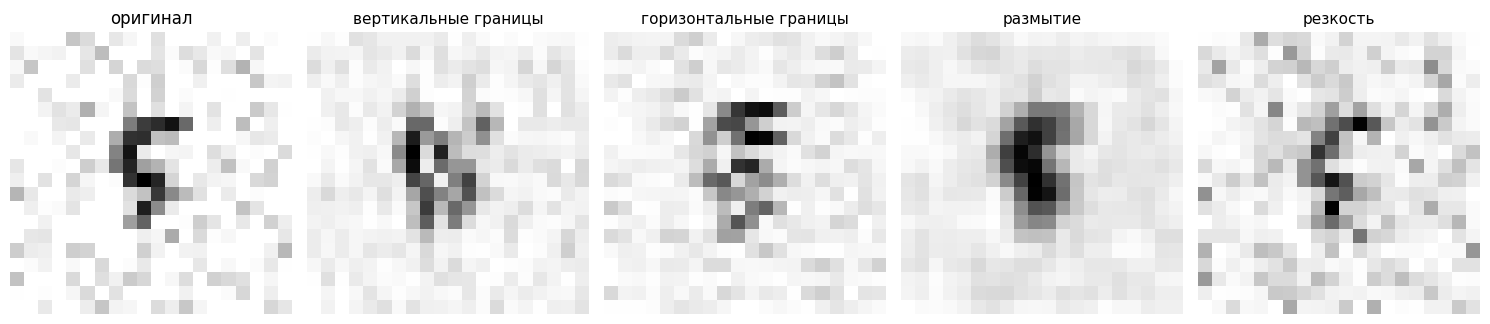

F.conv2d(x, k)              = 1.0
(x * k).sum()               = 1.0  ← корреляция, без отражения
(x * k.flip(-1, -2)).sum()  = 9.0  ← настоящая свёртка, с отражением


In [4]:
sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])
sobel_y = sobel_x.T.contiguous()
blur    = torch.ones(3, 3) / 9.0
sharpen = torch.tensor([[ 0., -1.,  0.],
                        [-1.,  5., -1.],
                        [ 0., -1.,  0.]])

kernels = {"вертикальные границы": sobel_x, "горизонтальные границы": sobel_y,
           "размытие": blur, "резкость": sharpen}

sample = torch.tensor(X_test_centre[0:1])           # (1, 1, 20, 20)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(sample[0, 0], cmap="gray_r"); axes[0].set_title("оригинал"); axes[0].axis("off")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    w = k.view(1, 1, 3, 3)
    out = F.conv2d(sample, w, padding=1)
    ax.imshow(out[0, 0].abs(), cmap="gray_r"); ax.set_title(name, fontsize=11); ax.axis("off")
plt.tight_layout(); plt.show()

# Свёртка или корреляция? Кладём ядро на окно ровно того же размера — тогда
# на выходе одно число, и видно, отражается ядро или нет.
x = torch.tensor([[[[1., 2., 3.], [4., 5., 6.], [7., 8., 9.]]]])
k = torch.tensor([[[[1., 0., 0.], [0., 0., 0.], [0., 0., 0.]]]])   # единица в углу

print("F.conv2d(x, k)              =", F.conv2d(x, k).item())
print("(x * k).sum()               =", (x * k).sum().item(), " ← корреляция, без отражения")
print("(x * k.flip(-1, -2)).sum()  =", (x * k.flip(-1, -2)).sum().item(),
      " ← настоящая свёртка, с отражением")

Проверим формулу размера выхода со слайда 23:

$$H_{out} = \left\lfloor \frac{H_{in} + 2p - d\,(k-1) - 1}{s} \right\rfloor + 1$$

In [5]:
def out_size(h_in, k, s=1, p=0, d=1):
    return (h_in + 2 * p - d * (k - 1) - 1) // s + 1


cases = [(20, 3, 1, 0, 1), (20, 3, 1, 1, 1), (20, 3, 2, 1, 1),
         (20, 5, 1, 0, 1), (20, 3, 1, 2, 2), (20, 2, 2, 0, 1)]

print(f"{'вход':>5} {'k':>3} {'s':>3} {'p':>3} {'d':>3} | {'формула':>8} {'PyTorch':>8}")
for h, k, s, p, d in cases:
    conv = nn.Conv2d(1, 1, k, stride=s, padding=p, dilation=d)
    real = conv(torch.zeros(1, 1, h, h)).shape[-1]
    mark = "" if real == out_size(h, k, s, p, d) else "   ← РАСХОЖДЕНИЕ"
    print(f"{h:>5} {k:>3} {s:>3} {p:>3} {d:>3} | {out_size(h,k,s,p,d):>8} {real:>8}{mark}")

 вход   k   s   p   d |  формула  PyTorch
   20   3   1   0   1 |       18       18
   20   3   1   1   1 |       20       20
   20   3   2   1   1 |       10       10
   20   5   1   0   1 |       16       16
   20   3   1   2   2 |       20       20
   20   2   2   0   1 |       10       10


---

## 3. Параметры и операции

Слайд 24 давал две формулы:

- параметров в `Conv2d(C_in, C_out, k×k)` — это `C_out · (C_in · k · k + 1)`;
- операций — примерно `H_out · W_out · C_out · C_in · k · k`.

Проверим первую на самом PyTorch и посмотрим, как обе ведут себя по ходу типичной сети:
разрешение падает вдвое по каждой оси, число каналов растёт вдвое — что
происходит со стоимостью слоя?

In [6]:
def conv_params(c_in, c_out, k, bias=True):
    return c_out * (c_in * k * k + (1 if bias else 0))


for c_in, c_out, k in [(3, 64, 3), (64, 128, 3), (256, 512, 3), (256, 64, 1)]:
    real = sum(p.numel() for p in nn.Conv2d(c_in, c_out, k).parameters())
    print(f"Conv2d({c_in:3d} → {c_out:3d}, {k}×{k}): формула {conv_params(c_in,c_out,k):>8} "
          f"| PyTorch {real:>8} {'✓' if real == conv_params(c_in,c_out,k) else '✗'}")

print()
print("Типичная свёрточная сеть на входе 224×224 (как VGG):")
print(f"{'блок':>6} {'разрешение':>12} {'каналов':>8} {'параметров':>12} {'операций, млн':>15}")
res, c_prev, tot_p, tot_f = 224, 3, 0, 0
for stage, c in enumerate([64, 128, 256, 512, 512], 1):
    p = conv_params(c_prev, c, 3)
    f = res * res * c * c_prev * 9
    tot_p += p; tot_f += f
    print(f"{stage:>6} {f'{res}×{res}':>12} {c:>8} {p:>12,} {f/1e6:>15.1f}")
    c_prev, res = c, res // 2
print(f"{'итого':>6} {'':>12} {'':>8} {tot_p:>12,} {tot_f/1e6:>15.1f}")

Conv2d(  3 →  64, 3×3): формула     1792 | PyTorch     1792 ✓
Conv2d( 64 → 128, 3×3): формула    73856 | PyTorch    73856 ✓
Conv2d(256 → 512, 3×3): формула  1180160 | PyTorch  1180160 ✓
Conv2d(256 →  64, 1×1): формула    16448 | PyTorch    16448 ✓

Типичная свёрточная сеть на входе 224×224 (как VGG):
  блок   разрешение  каналов   параметров   операций, млн
     1      224×224       64        1,792            86.7
     2      112×112      128       73,856           924.8
     3        56×56      256      295,168           924.8
     4        28×28      512    1,180,160           924.8
     5        14×14      512    2,359,808           462.4
 итого                          3,910,784          3323.7


Обратите внимание на форму таблицы. **Параметров к концу сети становится в тысячу раз
больше, а операций — примерно поровну.** Это не совпадение: понижая разрешение вдвое
по каждой оси, мы делим число позиций на четыре, а удваивая каналы и на входе, и на
выходе — умножаем стоимость одной позиции на четыре. Блоки 2, 3 и 4 в таблице стоят
буквально одинаково.

Выпадают два блока, и оба по понятной причине: **первый дёшев**, потому что у входа
всего три канала (а не 64 и не 128), **последний дёшев**, потому что каналы там
перестали удваиваться (512 → 512, а не 512 → 1024).

📌 Практический вывод: если сеть надо ускорить, смотреть надо на разрешение, а если
уменьшить в памяти — на каналы в конце. Это разные ручки, и крутят их в разные стороны.

---

## 4. Рецептивное поле — измеряем градиентом

Формула со слайда 25: стек из `L` слоёв `k×k` с шагом 1 даёт `RF = 1 + L·(k−1)`.
Проверять её на бумаге скучно, поэтому измерим напрямую: возьмём один нейрон
на выходе, посчитаем градиент по входу и посмотрим, у каких пикселей он ненулевой.
**Это ровно определение рецептивного поля** — какие входные пиксели влияют
на данный выход.

 слоёв   ядро |   формула 1+L(k-1)   измерено
     1    3×3 |                  3          3 ✓
     2    3×3 |                  5          5 ✓
     3    3×3 |                  7          7 ✓
     5    3×3 |                 11         11 ✓
     8    3×3 |                 17         17 ✓
     1    5×5 |                  5          5 ✓
     2    5×5 |                  9          9 ✓
     3    5×5 |                 13         13 ✓
     5    5×5 |                 21         21 ✓
     8    5×5 |                 33         33 ✓


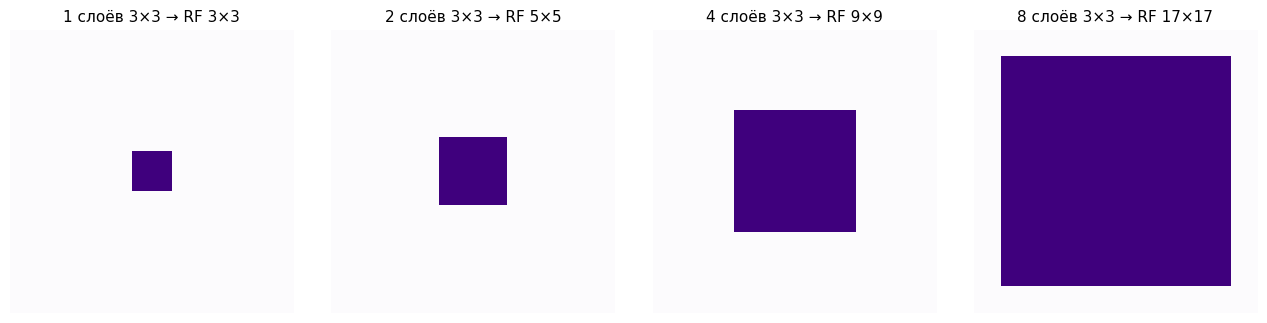

In [7]:
def measure_rf(n_layers, k=3, stride=1, size=61):
    """Ненулевой градиент центрального выхода по входу = рецептивное поле."""
    layers = []
    for _ in range(n_layers):
        conv = nn.Conv2d(1, 1, k, stride=stride, padding=k // 2)
        nn.init.constant_(conv.weight, 1.0)      # веса не важны, важна связность
        nn.init.constant_(conv.bias, 0.0)
        layers.append(conv)
    net = nn.Sequential(*layers)

    x = torch.zeros(1, 1, size, size, requires_grad=True)
    out = net(x)
    c = out.shape[-1] // 2
    out[0, 0, c, c].backward()
    mask = (x.grad[0, 0].abs() > 0).numpy()
    ys, xs = np.nonzero(mask)
    return ys.max() - ys.min() + 1, mask


print(f"{'слоёв':>6} {'ядро':>6} | {'формула 1+L(k-1)':>18} {'измерено':>10}")
for k in (3, 5):
    for L in (1, 2, 3, 5, 8):
        rf, _ = measure_rf(L, k)
        pred = 1 + L * (k - 1)
        print(f"{L:>6} {f'{k}×{k}':>6} | {pred:>18} {rf:>10} {'✓' if rf == pred else '✗'}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, L in zip(axes, (1, 2, 4, 8)):
    rf, mask = measure_rf(L, 3)
    ax.imshow(mask[20:41, 20:41], cmap="Purples")
    ax.set_title(f"{L} слоёв 3×3 → RF {rf}×{rf}", fontsize=11); ax.axis("off")
plt.tight_layout(); plt.show()

Восемь слоёв 3×3 дают рецептивное поле всего 17×17. Это и есть причина, по которой
классификационные сети агрессивно понижают разрешение: **без пулинга и свёрток с шагом
рецептивное поле растёт линейно по числу слоёв, и добраться до «всей картинки 224×224»
стоило бы больше сотни слоёв.** С понижением разрешения оно растёт геометрически.

📌 Полезное следствие: если вы решаете задачу, где важен контекст всей сцены,
а сеть его «не видит» — считайте рецептивное поле. Часто оказывается, что оно
физически меньше объекта, который вы просите найти.

---

## 5. Полносвязная сеть против свёрточной

Главный эксперимент семинара. Лекция утверждала: полносвязная сеть плоха для картинок,
потому что (а) у неё взрывается число параметров и (б) она ничего не знает про сдвиг.
Первое проверять неинтересно — это арифметика. Проверим второе, и проверим **честно**:
соберём сети с примерно одинаковым числом параметров, чтобы разница не объяснялась
размером модели.

Обе сети обучаем на цифрах **строго в центре** и тестируем дважды: в центре и со сдвигом.

In [8]:
def make_mlp(n_out=10):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(CANVAS * CANVAS, 128), nn.BatchNorm1d(128), nn.ReLU(),
        nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(),
        nn.Linear(64, n_out),
    )


class CNN(nn.Module):
    """Сеть ровно той формы, что на слайде: n × [свёртка → BN → ReLU → пулинг] + голова.

    Голова — глобальный average pooling плюс один линейный слой. Именно GAP делает
    её независимой от размера входа (слайд 35).
    """

    def __init__(self, n_out=10, width=32):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            nn.Conv2d(1, w, 3, padding=1),     nn.BatchNorm2d(w),     nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(w, 2 * w, 3, padding=1), nn.BatchNorm2d(2 * w), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(2 * w, 2 * w, 3, padding=1), nn.BatchNorm2d(2 * w), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.head = nn.Linear(2 * w, n_out)

    def forward(self, x):
        return self.head(self.features(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


print("MLP:", f"{n_params(make_mlp()):,}", "параметров")
print("CNN:", f"{n_params(CNN()):,}", "параметров")

MLP: 60,618 параметров
CNN: 56,714 параметров


In [9]:
def train(model, X, y, epochs=25, lr=3e-3, seed=1, params=None,
          freeze_features=False, batch_size=64):
    """Общий цикл обучения. Сид ставится ВНУТРИ: перемешивание в DataLoader

    расходует глобальный генератор, и без своего сида «одинаковые» прогоны
    разъезжаются.
    """
    torch.manual_seed(seed)
    loader = DataLoader(
        TensorDataset(torch.tensor(X), torch.tensor(y)),
        batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed))
    opt = torch.optim.AdamW(params if params is not None else model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    for _ in range(epochs):
        model.train()
        if freeze_features:
            # у замороженного бэкбона BatchNorm держим в eval: иначе бегущие
            # статистики поедут на нескольких десятках картинок (слайд 47)
            model.features.eval()
        for xb, yb in loader:
            opt.zero_grad()
            criterion(model(xb), yb).backward()
            opt.step()
    return model


@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return float((model(torch.tensor(X)).argmax(1).numpy() == y).mean())


results = {}
for name, factory in (("MLP", make_mlp), ("CNN", CNN)):
    torch.manual_seed(0)
    model = factory()
    train(model, X_train, y_train)
    results[name] = dict(model=model,
                         centre=accuracy(model, X_test_centre, y_test),
                         shift=accuracy(model, X_test_shift, y_test))
    print(f"{name:4s} параметров {n_params(model):>7,} | "
          f"тест в центре {results[name]['centre']:.3f} | "
          f"тест со сдвигом {results[name]['shift']:.3f}")
print(f"\n(случайное угадывание дало бы {1/10:.3f})")

MLP  параметров  60,618 | тест в центре 0.940 | тест со сдвигом 0.123


CNN  параметров  56,714 | тест в центре 0.974 | тест со сдвигом 0.608

(случайное угадывание дало бы 0.100)


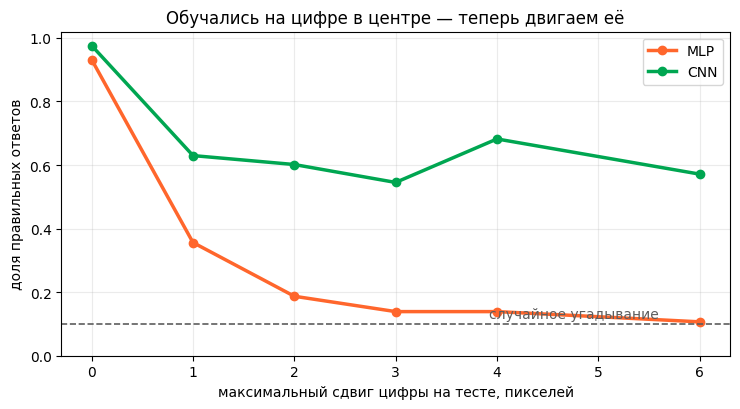

MLP ±0:0.932 ±1:0.356 ±2:0.187 ±3:0.139 ±4:0.139 ±6:0.107
CNN ±0:0.976 ±1:0.630 ±2:0.602 ±3:0.545 ±4:0.682 ±6:0.571


In [10]:
# Насколько быстро всё разваливается? Сдвигаем тест на ±j пикселей.
shifts = [0, 1, 2, 3, 4, 6]
curves = {name: [] for name in results}
for j in shifts:
    # генератор один и тот же для всех j: меняется только величина сдвига,
    # шум и порядок картинок остаются теми же
    Xj = place(IMAGES[i_test], np.random.default_rng(50), "jitter", jitter=j)
    for name, r in results.items():
        curves[name].append(accuracy(r["model"], Xj, y_test))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, color in (("MLP", "#FF662C"), ("CNN", "#00A651")):
    ax.plot(shifts, curves[name], "o-", lw=2.5, color=color, label=name)
ax.axhline(0.1, ls="--", lw=1.2, color="#5D5D5D")
ax.text(5.6, 0.12, "случайное угадывание", ha="right", fontsize=10, color="#5D5D5D")
ax.set_xlabel("максимальный сдвиг цифры на тесте, пикселей")
ax.set_ylabel("доля правильных ответов")
ax.set_ylim(0, 1.02); ax.legend(); ax.grid(alpha=0.25)
ax.set_title("Обучались на цифре в центре — теперь двигаем её")
plt.tight_layout(); plt.show()

for name in curves:
    print(name, " ".join(f"±{j}:{a:.3f}" for j, a in zip(shifts, curves[name])))

**Что здесь важно прочитать правильно.**

Полносвязная сеть валится с обрыва: одного пикселя сдвига хватает, чтобы она потеряла
больше половины качества, а на большом сдвиге падает почти до случайного угадывания.
Ничего удивительного: для неё пиксель `(3, 7)` и пиксель `(9, 13)` — два независимых
входа, и связи между ними нет никакой.

Свёрточная тоже проседает на первом же пикселе, но не обваливается: она выходит
на плато примерно 0,55–0,68 и остаётся вшестеро выше случайного угадывания —
хотя **сдвинутых картинок не видела ни разу**. Это работает разделение весов:
одно и то же ядро едет по всей картинке, поэтому «палочка» в новом месте всё равно
находится.

⚠️ Кривая CNN немонотонна (на ±4 качество выше, чем на ±3). Это не ошибка: у нас
один прогон и одна случайная раскладка теста, а разные диапазоны сдвига дают разный
набор краевых положений, где цифра частично обрезается холстом. Правильный способ
такое утверждать — усреднить по нескольким сидам; см. задание 8.

⚠️ **Но обратите внимание: свёрточная сеть тоже просела, и заметно.** Тезис
«CNN инвариантна к сдвигу» в чистом виде **неверен**, и это ровно та путаница
с эквивариантностью и инвариантностью, о которой была речь на слайде 31. Свёртка
эквивариантна: сдвинули вход — сдвинулась карта признаков. Глобальный пулинг в конце
добавляет инвариантности, но не бесплатно: на границах холста цифра обрезается, статистики
BatchNorm подобраны под центрированные картинки, да и обучалась сеть на одном
положении. Чтобы получить настоящую устойчивость, сдвиг нужно показать сети явно —
этим и займёмся дальше.

---

## 6. Аугментации: какая помогает, а какая портит

Аугментация — это способ сказать сети «вот такие преобразования не меняют ответ».
Если преобразование выбрано правильно, качество растёт. Если неправильно —
вы своими руками учите сеть неправде.

Проверим оба случая. Правильная аугментация для нашей задачи — **сдвиг**
(двойка остаётся двойкой, куда её ни положи). Неправильная — **горизонтальное
отражение**: отражённая двойка двойкой быть перестаёт.

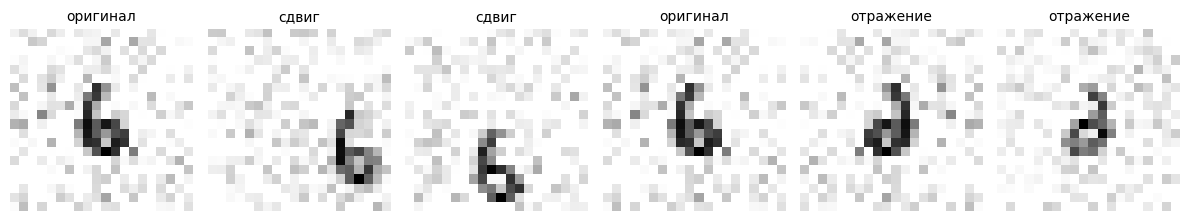

In [11]:
X_shift_aug = np.concatenate([
    X_train,
    place(IMAGES[i_train], np.random.default_rng(4), "random"),
])
X_flip_aug = np.concatenate([X_train, X_train[:, :, :, ::-1].copy()])
y_aug = np.concatenate([y_train, y_train])

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, img, t in zip(axes[:3], X_shift_aug[[0, len(X_train), len(X_train) + 1]],
                      ["оригинал", "сдвиг", "сдвиг"]):
    ax.imshow(img[0], cmap="gray_r"); ax.set_title(t, fontsize=10); ax.axis("off")
for ax, img, t in zip(axes[3:], X_flip_aug[[0, len(X_train), len(X_train) + 1]],
                      ["оригинал", "отражение", "отражение"]):
    ax.imshow(img[0], cmap="gray_r"); ax.set_title(t, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

In [12]:
aug_results = {}
for aug_name, Xa in (("без аугментации", (X_train, y_train)),
                     ("+ случайный сдвиг", (X_shift_aug, y_aug)),
                     ("+ отражение по горизонтали", (X_flip_aug, y_aug))):
    for net_name, factory in (("MLP", make_mlp), ("CNN", CNN)):
        torch.manual_seed(0)
        model = factory()
        train(model, Xa[0], Xa[1])
        aug_results[(aug_name, net_name)] = (
            accuracy(model, X_test_centre, y_test),
            accuracy(model, X_test_shift, y_test))

print(f"{'аугментация':<28} {'сеть':<5} {'центр':>7} {'сдвиг':>7}")
for (aug_name, net_name), (a_c, a_s) in aug_results.items():
    print(f"{aug_name:<28} {net_name:<5} {a_c:>7.3f} {a_s:>7.3f}")

аугментация                  сеть    центр   сдвиг
без аугментации              MLP     0.940   0.123
без аугментации              CNN     0.974   0.608
+ случайный сдвиг            MLP     0.903   0.249
+ случайный сдвиг            CNN     0.974   0.958
+ отражение по горизонтали   MLP     0.901   0.115
+ отражение по горизонтали   CNN     0.942   0.497


Три вывода, каждый видно в таблице.

1. **Сдвиговая аугментация чинит свёрточную сеть почти полностью.** Ей достаточно
   показать, что цифра бывает не в центре, — и разделение весов доделывает остальное.
2. **Полносвязной сети та же аугментация помогает гораздо слабее.** У неё нет механизма,
   который переносил бы выученное из одного положения в другое: каждое положение
   приходится запоминать отдельно, а параметров на 169 положений не хватает.
   Аугментация не заменяет правильную архитектуру, она её дополняет.
3. **Отражение делает хуже**, и это не шум замера: мы буквально показали сети зеркальные
   цифры с теми же метками и потребовали считать их одним классом. Отсюда практическое
   правило: аугментация — это утверждение о вашей задаче, а не универсальная кнопка
   «сделать лучше». Для цифр отражение неверно, для фотографий кошек — верно,
   для дорожных знаков — снова неверно.

---

## 7. Transfer learning

Теперь главное практическое умение из лекции. Сценарий ровно тот, что описан на слайде 46:
есть большая задача с большим количеством данных и есть своя маленькая задача,
на которую данных почти нет.

- **Задача A («ImageNet»)**: цифры 0–4, все доступные картинки, случайное положение.
  На ней предобучаем бэкбон.
- **Задача B («ваша задача»)**: цифры 5–9. Классы **другие**, картинок мало.

Сравниваем три режима со слайда 47 плюс один антипример:

| режим | что обучаем |
|---|---|
| с нуля | вся сеть, случайная инициализация |
| feature extraction | только голова, бэкбон заморожен |
| fine-tuning | вся сеть, но с маленьким темпом обучения |
| fine-tuning, большой η | вся сеть с обычным темпом — антипример |

⚠️ **Честное предупреждение о том, как этот раздел готовился.** В первой версии
transfer learning здесь **не работал**: обучение с нуля обгоняло оба режима переноса.
Причина оказалась не в коде, а в постановке: задача была слишком лёгкой, а «мало данных»
означало 150 картинок, чего для цифр 8×8 более чем достаточно. Тезис лекции верен
не всегда, а при условии «своих данных действительно мало» — и увидеть его можно,
только поставив задачу так, чтобы это условие выполнялось. Поэтому дальше мы смотрим
не одно число, а **зависимость от размера обучающей выборки**.

In [13]:
mask_A = np.isin(LABELS, [0, 1, 2, 3, 4])
idx_A = np.where(mask_A)[0]
idx_B = np.where(~mask_A)[0]
rng_split = np.random.default_rng(0)
rng_split.shuffle(idx_A)
rng_split.shuffle(idx_B)

X_A = place(IMAGES[idx_A], np.random.default_rng(11), "random")
y_A = LABELS[idx_A]                       # классы 0…4
X_B = place(IMAGES[idx_B], np.random.default_rng(12), "random")
y_B = LABELS[idx_B] - 5                   # классы 5…9 → 0…4

X_B_test, y_B_test = X_B[500:], y_B[500:]
print("задача A:", len(X_A), "картинок | задача B: пул", len(X_B),
      "| фиксированный тест B:", len(X_B_test))

torch.manual_seed(0)
backbone = CNN(n_out=5)
train(backbone, X_A, y_A, epochs=40, lr=3e-3, seed=0)
print("качество бэкбона на своей задаче A:", round(accuracy(backbone, X_A, y_A), 3))

задача A: 901 картинок | задача B: пул 896 | фиксированный тест B: 396


качество бэкбона на своей задаче A: 1.0


In [14]:
def transfer_run(mode, X_tr, y_tr, epochs=80):
    if mode == "с нуля":
        torch.manual_seed(0)
        model = CNN(n_out=5)
        return train(model, X_tr, y_tr, epochs=epochs, lr=3e-3, seed=1)

    model = copy.deepcopy(backbone)
    model.head = nn.Linear(model.head.in_features, 5)   # своя голова под свои классы

    if mode == "feature extraction":
        for p in model.features.parameters():
            p.requires_grad = False
        return train(model, X_tr, y_tr, epochs=epochs, lr=3e-3, seed=1,
                     params=model.head.parameters(), freeze_features=True)
    if mode == "fine-tuning":
        return train(model, X_tr, y_tr, epochs=epochs, lr=3e-4, seed=1)
    if mode == "fine-tuning, большой η":
        return train(model, X_tr, y_tr, epochs=epochs, lr=3e-3, seed=1)
    raise ValueError(mode)


MODES = ["с нуля", "feature extraction", "fine-tuning", "fine-tuning, большой η"]
PER_CLASS = [3, 5, 10, 25, 50]

table = {m: [] for m in MODES}
for k in PER_CLASS:
    n = k * 5
    X_tr, y_tr = X_B[:n], y_B[:n]
    for mode in MODES:
        table[mode].append(accuracy(transfer_run(mode, X_tr, y_tr), X_B_test, y_B_test))
    print(f"по {k:>2} примеров на класс ({n:>3} всего): " +
          "  ".join(f"{m}={table[m][-1]:.3f}" for m in MODES))

по  3 примеров на класс ( 15 всего): с нуля=0.369  feature extraction=0.447  fine-tuning=0.394  fine-tuning, большой η=0.508


по  5 примеров на класс ( 25 всего): с нуля=0.465  feature extraction=0.472  fine-tuning=0.561  fine-tuning, большой η=0.583


по 10 примеров на класс ( 50 всего): с нуля=0.619  feature extraction=0.508  fine-tuning=0.644  fine-tuning, большой η=0.732


по 25 примеров на класс (125 всего): с нуля=0.823  feature extraction=0.553  fine-tuning=0.775  fine-tuning, большой η=0.854


по 50 примеров на класс (250 всего): с нуля=0.919  feature extraction=0.558  fine-tuning=0.896  fine-tuning, большой η=0.909


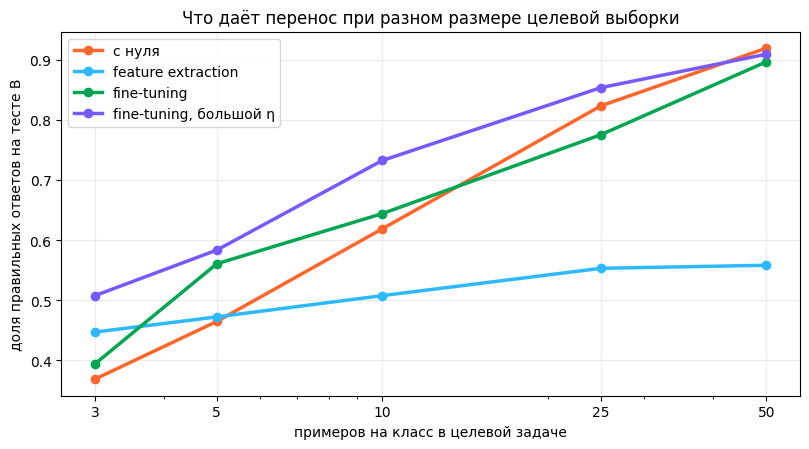

In [15]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
colors = {"с нуля": "#FF662C", "feature extraction": "#2CB9FF",
          "fine-tuning": "#00A651", "fine-tuning, большой η": "#7759FF"}
for mode in MODES:
    ax.plot(PER_CLASS, table[mode], "o-", lw=2.5, color=colors[mode], label=mode)
ax.set_xlabel("примеров на класс в целевой задаче")
ax.set_ylabel("доля правильных ответов на тесте B")
ax.set_xscale("log"); ax.set_xticks(PER_CLASS); ax.set_xticklabels(PER_CLASS)
ax.grid(alpha=0.25); ax.legend()
ax.set_title("Что даёт перенос при разном размере целевой выборки")
plt.tight_layout(); plt.show()

**Как читать этот график.** Он воспроизводит матрицу со слайда 48, только развёрнутую
по одной оси — «сколько у вас данных».

1. **Слева, где примеров по три-пять на класс, перенос выигрывает.** Случайно
   инициализированной сети просто не из чего выучить фильтры, предобученной —
   не нужно, они уже есть.
2. **Feature extraction рано упирается в потолок.** Его кривая почти горизонтальна
   (0,45 → 0,56 при росте выборки в семнадцать раз) и уже с десяти примеров на класс
   проигрывает обучению с нуля. Замороженный бэкбон выучил признаки под **чужие**
   классы 0–4, и линейная голова поверх фиксированного 64-мерного вектора больше
   из них не вытянет. Вот это плато — и есть практический признак того,
   что бэкбон пора размораживать.
3. **Справа обучение с нуля догоняет и обгоняет всех.** При пятидесяти примерах
   на класс задача перестала быть «малоданной», и предобучение больше ничего
   не добавляет.

⚠️ **А вот правило «разморозили бэкбон — уменьшайте η» со слайда 47 здесь
не подтвердилось**: fine-tuning с большим шагом выиграл почти во всех точках.
И это не повод считать правило неверным — это повод понять, откуда оно берётся.
Правило защищает предобученные признаки от разрушения, а защищать их надо тогда,
когда они добыты на данных, которых у вас нет и не будет. У нас же задачи A и B —
это одни и те же рукописные цифры, снятые одинаково; «разрушить» бэкбон большим
шагом не страшно, потому что целевые данные несут ровно ту же информацию.
Проверьте это сами в задании 5: сделайте домен далёким — и увидите, как правило
включается.

📌 Общий вывод, который важнее конкретных чисел: **выигрыш от transfer learning
измеряется, а не предполагается.** Прежде чем строить пайплайн вокруг предобученного
бэкбона, стоит потратить полчаса и построить вот такой же график для своей задачи.
Все четыре линии на нём пересекаются, и какая окажется сверху — зависит от того,
сколько у вас данных и насколько ваш домен далёк от того, на котором учили бэкбон.

---

## 8. Настоящий предобученный бэкбон

До сих пор бэкбон мы «предобучали» сами. В реальной задаче его берут готовым
из `torchvision` — здесь это ResNet18, обученный на ImageNet. При первом запуске
скачаются веса, около 45 МБ; дальше они лежат в кэше `~/.cache/torch`. Та же сеть
понадобится на семинаре 6, так что скачивание не пропадёт.

Разберём два вопроса:

1. **Как подключить бэкбон правильно.** Главная ловушка тут не в коде модели,
   а в препроцессинге.
2. **Выиграет ли знаменитый ImageNet-бэкбон у нашего самодельного** из раздела 7
   на задаче B.

In [16]:
import torchvision
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.IMAGENET1K_V1
CATEGORIES = weights.meta["categories"]      # 1000 классов ImageNet

# ⚠️ Препроцессинг берём ИЗ ВЕСОВ, а не пишем руками: он должен быть тем же,
# что при предобучении.
preprocess = weights.transforms()
print(preprocess)

resnet = torchvision.models.resnet18(weights=weights).eval()
print(f"параметров в ResNet18: {n_params(resnet):,} "
      f"(в нашей CNN из раздела 7 — {n_params(backbone):,})")

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
параметров в ResNet18: 11,689,512 (в нашей CNN из раздела 7 — 56,389)


### 8.1. Препроцессинг — часть модели

Сеть видела на обучении картинки, нормализованные **ровно этими** `mean` и `std`.
Другой масштаб входа — это другие данные, и сеть об этом не предупредит.

Проверим на двух фотографиях, которые лежат прямо в `scikit-learn`. Сравним
правильный препроцессинг с тремя типичными ошибками:

- **забыли `mean/std`** — пиксели в 0…1, как их отдаёт `ToTensor()`;
- **забыли и деление на 255** — пиксели в 0…255;
- **перепутали каналы** — картинку прочитали через OpenCV, а он отдаёт BGR.

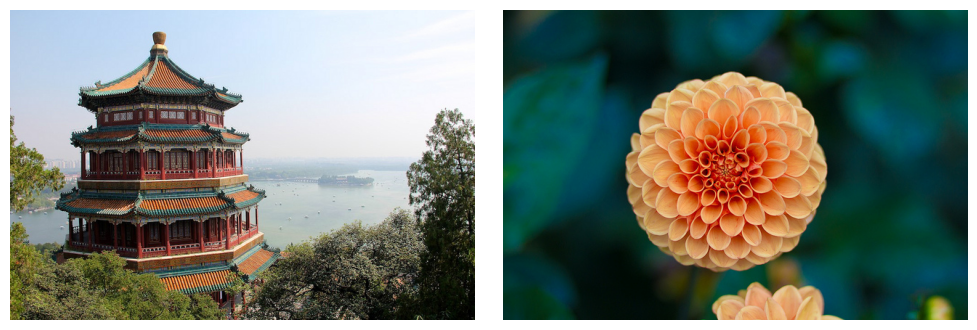

фото 1:
   правильно         → bell cote (0.53)
   забыли mean/std   → bell cote (0.28)
   пиксели 0…255     → plunger (1.00)
   BGR вместо RGB    → boathouse (0.27)
фото 2:
   правильно         → honeycomb (0.67)
   забыли mean/std   → honeycomb (0.96)
   пиксели 0…255     → dishwasher (0.57)
   BGR вместо RGB    → honeycomb (0.44)


In [17]:
from sklearn.datasets import load_sample_images

photos = load_sample_images().images                 # две фотографии 427×640, RGB
MEAN = torch.tensor(preprocess.mean).view(3, 1, 1)
STD = torch.tensor(preprocess.std).view(3, 1, 1)


def top1(x):
    with torch.no_grad():
        p = resnet(x[None]).softmax(1)[0]
    i = int(p.argmax())
    return f"{CATEGORIES[i]} ({p[i]:.2f})"


fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, im in zip(axes, photos):
    ax.imshow(im); ax.axis("off")
plt.tight_layout(); plt.show()

for k, im in enumerate(photos, 1):
    x = torch.from_numpy(im.copy()).permute(2, 0, 1)  # HWC → CHW, uint8
    good = preprocess(x)
    in01 = good * STD + MEAN                           # тот же кадр, но без mean/std
    variants = {"правильно": good,
                "забыли mean/std": in01,
                "пиксели 0…255": in01 * 255,
                "BGR вместо RGB": preprocess(x.flip(0))}
    print(f"фото {k}:")
    for name, v in variants.items():
        print(f"   {name:17s} → {top1(v)}")

**Что видно.** Грубая ошибка с масштабом 0…255 даёт **явную ерунду**: вантуз
с уверенностью 1,00 и посудомоечную машину. Такую ошибку заметят сразу.

Опасны две другие. Без `mean/std` и с перепутанными каналами ответы остаются
**правдоподобными**, меняется только уверенность, причём не обязательно в меньшую
сторону. Ничто не сигналит об ошибке: пайплайн «работает», а качество после дообучения
может оказаться ниже, чем могло бы, и понять почему трудно.
Отсюда правило: препроцессинг не пишут по памяти, а берут из `weights.transforms()`.

📌 На втором фото георгин, а сеть говорит «пчелиные соты». Это не ошибка препроцессинга:
класса «георгин» в ImageNet нет, а плотные трубчатые лепестки правда похожи на соты.

### 8.2. ImageNet против своего бэкбона на задаче B

Возвращаемся к задаче B (цифры 5–9, мало примеров). У нас теперь два предобученных
бэкбона:

- **наш** из раздела 7: 56 тысяч параметров, учился на соседней задаче — цифрах 0–4;
- **ResNet18**: 11 миллионов параметров, учился на миллионе фотографий ImageNet.

⚠️ `weights.transforms()` целиком здесь не подходит: он рассчитан на фотографии.
`Resize(256)` и `CenterCrop(224)` срежут края холста, а цифры у нас стоят где угодно,
в том числе у самого края. Поэтому берём из него только то, что обязано совпадать, —
`mean` и `std`. Картинку 20×20 растягиваем до 112×112 сами, а один серый канал
повторяем трижды: ResNet ждёт RGB.

In [18]:
RES = 112


def to_resnet(X):
    """Холсты N×1×20×20 → вход ResNet: 3 канала, 112×112, нормализация ImageNet."""
    x = torch.tensor(X).clamp(0, 1).repeat(1, 3, 1, 1)
    x = F.interpolate(x, size=RES, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD


# Feature extraction: бэкбон заморожен, поэтому признаки считаем один раз.
body = nn.Sequential(*list(resnet.children())[:-1], nn.Flatten()).eval()   # без fc
with torch.no_grad():
    FEATS_B = torch.cat([body(to_resnet(X_B[i:i + 128])) for i in range(0, len(X_B), 128)])
FEATS_B = FEATS_B.numpy()
print("признаки ResNet18:", FEATS_B.shape)

resnet_fx = []
for k in PER_CLASS:
    n = k * 5
    head = train(nn.Linear(512, 5), FEATS_B[:n], y_B[:n], epochs=200, lr=1e-2)
    resnet_fx.append(accuracy(head, FEATS_B[500:], y_B_test))
    print(f"по {k:>2} примеров на класс: ResNet18, feature extraction = {resnet_fx[-1]:.3f}"
          f"   | наш бэкбон, feature extraction = {table['feature extraction'][PER_CLASS.index(k)]:.3f}")

признаки ResNet18: (896, 512)
по  3 примеров на класс: ResNet18, feature extraction = 0.245   | наш бэкбон, feature extraction = 0.447
по  5 примеров на класс: ResNet18, feature extraction = 0.348   | наш бэкбон, feature extraction = 0.472
по 10 примеров на класс: ResNet18, feature extraction = 0.374   | наш бэкбон, feature extraction = 0.508


по 25 примеров на класс: ResNet18, feature extraction = 0.447   | наш бэкбон, feature extraction = 0.553


по 50 примеров на класс: ResNet18, feature extraction = 0.525   | наш бэкбон, feature extraction = 0.558


Теперь fine-tuning — ровно так, как его пишут на практике: замораживаем всё,
размораживаем последний блок `layer4`, ставим свою голову и даём им **разные
темпы обучения**. Считаем только для 10 и 50 примеров на класс: на CPU это
около минуты.

📌 Приём с разными темпами для бэкбона и головы (discriminative learning rates)
на лекцию не поместился, но используется постоянно. Голова инициализирована случайно,
и её надо двигать быстро; бэкбон уже хорош, и его надо двигать осторожно.

In [19]:
X_B_test_r = to_resnet(X_B_test)


def resnet_finetune(n, epochs=30):
    torch.manual_seed(0)
    model = torchvision.models.resnet18(weights=weights)
    for p in model.parameters():                      # заморозили всё
        p.requires_grad = False
    for p in model.layer4.parameters():               # разморозили последний блок
        p.requires_grad = True
    model.fc = nn.Linear(model.fc.in_features, 5)     # своя голова (обучается по умолчанию)

    opt = torch.optim.AdamW([
        {"params": model.layer4.parameters(), "lr": 1e-4},   # бэкбону — маленький шаг
        {"params": model.fc.parameters(),     "lr": 1e-3},   # голове — обычный
    ])
    loader = DataLoader(TensorDataset(to_resnet(X_B[:n]), torch.tensor(y_B[:n])),
                        batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(1))
    frozen = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]
    for _ in range(epochs):
        model.train()
        for m in frozen:                              # BatchNorm замороженной части — в eval
            m.eval()
        for xb, yb in loader:
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(X_B_test_r[i:i + 128]) for i in range(0, len(X_B_test_r), 128)])
    return float((pred.argmax(1).numpy() == y_B_test).mean())


FT_K = [10, 50]
resnet_ft = []
for k in FT_K:
    resnet_ft.append(resnet_finetune(k * 5))
    print(f"по {k:>2} примеров на класс: ResNet18, fine-tuning layer4 = {resnet_ft[-1]:.3f}"
          f"   | наш бэкбон, fine-tuning = {table['fine-tuning'][PER_CLASS.index(k)]:.3f}")

по 10 примеров на класс: ResNet18, fine-tuning layer4 = 0.417   | наш бэкбон, fine-tuning = 0.644


по 50 примеров на класс: ResNet18, fine-tuning layer4 = 0.672   | наш бэкбон, fine-tuning = 0.896


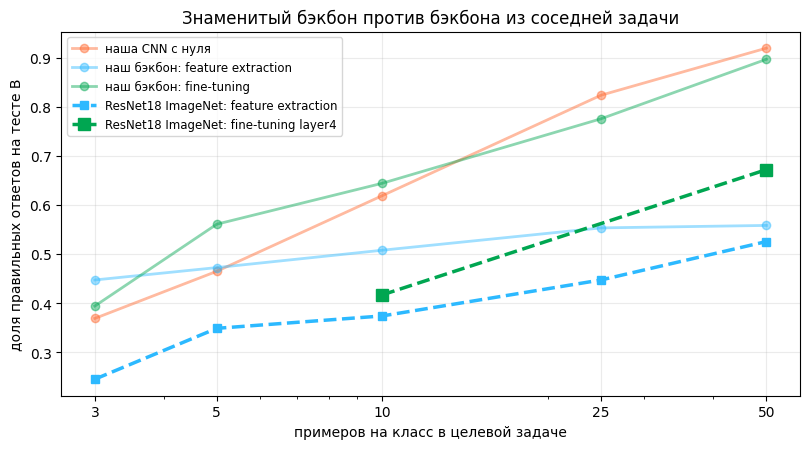

In [20]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
for mode in ["с нуля", "feature extraction", "fine-tuning"]:
    ax.plot(PER_CLASS, table[mode], "o-", lw=2, alpha=0.45, color=colors[mode],
            label=f"наш бэкбон: {mode}" if mode != "с нуля" else "наша CNN с нуля")
ax.plot(PER_CLASS, resnet_fx, "s--", lw=2.5, color=colors["feature extraction"],
        label="ResNet18 ImageNet: feature extraction")
ax.plot(FT_K, resnet_ft, "s--", lw=2.5, ms=9, color=colors["fine-tuning"],
        label="ResNet18 ImageNet: fine-tuning layer4")
ax.set_xlabel("примеров на класс в целевой задаче")
ax.set_ylabel("доля правильных ответов на тесте B")
ax.set_xscale("log"); ax.set_xticks(PER_CLASS); ax.set_xticklabels(PER_CLASS)
ax.grid(alpha=0.25); ax.legend(fontsize=8.5)
ax.set_title("Знаменитый бэкбон против бэкбона из соседней задачи")
plt.tight_layout(); plt.show()

**Как читать этот график.** ResNet18 проигрывает нашему крошечному бэкбону
в обоих режимах, хотя параметров у него в двести раз больше и учился он на миллионе
картинок. И это не ошибка подключения: препроцессинг правильный, код ровно тот,
что пишут на практике.

Дело в **близости доменов** — второй оси матрицы со слайда 48. Наш бэкбон учился
на тех же зашумлённых цифрах 20×20, только на других классах. ResNet18 учился
на фотографиях: собаках, машинах, текстурах. Растянутая шумная цифра на чёрном фоне
на них не похожа, и его признаки подходят к ней плохо.

Поэтому «берём ImageNet-бэкбон» — это правило по умолчанию **для фотографий**,
а не для любых картинок. На семинаре 6 тот же ResNet18 будет работать с фотографиями
машин и там заработает сразу. На рентгеновских снимках, спутниковых картах или
спектрограммах выигрыш надо мерить так же, как мы только что сделали.
Если есть бэкбон, обученный на близком домене, даже маленький, он может оказаться
ценнее знаменитого.

---

## 9. Что попробовать самостоятельно

1. **Голова сети.** В классе `CNN` голова — это `AdaptiveAvgPool2d(1)` плюс `Linear`.
   Замените GAP на `nn.Flatten()` с соответствующим `Linear` (посчитайте размер сами
   формулой из раздела 2) и повторите эксперимент из раздела 5. Насколько сильнее
   просядет качество на сдвинутом тесте? Это прямая проверка тезиса со слайда 35
   о том, что именно GAP даёт независимость от положения.
2. **Размер холста.** Поставьте `CANVAS = 32` и пересоберите данные. Что произойдёт
   с полносвязной сетью (число входов вырастет с 400 до 1024) и что — со свёрточной
   (число параметров не изменится вообще)? Это тезис про взрыв параметров со слайда 6,
   измеренный.
3. **Рецептивное поле и пулинг.** В `measure_rf` добавьте `nn.MaxPool2d(2)` между
   свёртками и измерьте RF для 2, 3 и 4 блоков. Во сколько раз быстрее оно растёт?
   Сравните с формулой для стека без пулинга.
4. **Аугментации.** Добавьте к сдвигу поворот на небольшой угол (можно через
   `torchvision.transforms.functional.rotate` или руками через `scipy.ndimage.rotate`)
   и шум. Какая комбинация даёт лучший результат на сдвинутом тесте? Найдите угол,
   начиная с которого поворот начинает вредить, — и объясните, какие именно цифры
   он ломает первыми.
5. **Где ломается перенос.** В разделе 7 задачи A и B — соседние (это всё цифры).
   Сделайте домен далёким: обучите бэкбон на цифрах, а перенесите на классификацию
   **положения** цифры (левая половина холста против правой). Помогает ли
   предобучение? Почему результат такой?
6. **Сколько замораживать.** Сейчас режимов два: всё заморожено или ничего.
   Заморозьте только первый свёрточный блок, потом первые два. Постройте
   зависимость качества от числа замороженных блоков при 10 примерах на класс
   и при 50. Совпадает ли картина с рекомендациями слайда 47?
7. **Темп обучения при fine-tuning.** В таблице раздела 7 два режима fine-tuning
   отличаются только шагом. Постройте зависимость качества от `lr`
   (от `1e-5` до `1e-2`) при 10 примерах на класс. Где оптимум и насколько он острый?
8. **Сколько верить одному прогону.** Кривая CNN в разделе 5 немонотонна. Прогоните
   тот же эксперимент с пятью разными сидами (`torch.manual_seed` перед созданием
   модели и `seed=` в `train`) и нарисуйте среднее с разбросом. Остаётся ли
   немонотонность? Это общая привычка, которую стоит завести: **разница меньше
   разброса по сидам — это не разница.**
9. **Число каналов.** У `CNN` есть параметр `width`. Постройте зависимость качества
   и числа параметров от `width` ∈ {8, 16, 32, 64} на задаче из раздела 5.
   Где выходит на плато?